# Tech Challenge Fase 2 - Demonstração (Projeto 1)

Otimização por **algoritmo genético** dos modelos de diagnóstico da Fase 1 e **interpretação com LLM**.

Este notebook só **demonstra** o sistema. O código está em `src/tc2` e os experimentos completos rodam com
`python scripts/run_optimization.py` (os resultados abaixo são lidos de `results/`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, Markdown, display
from tc2.data import load_data
from tc2.models import MODEL_NAMES, original_pipeline, evaluate
data = load_data()

## 1. Baseline: os modelos da Fase 1 (mesmo split, mesmos números)

In [2]:
pd.DataFrame({m: evaluate(original_pipeline(m).fit(data.X_train, data.y_train), data.X_test, data.y_test)
              for m in MODEL_NAMES}).round(4)

,random_forest,logistic_regression
recall_maligno,0.9286,0.9762
precision_maligno,0.9512,0.9762
f1_maligno,0.9398,0.9762
f2_maligno,0.9330,0.9762
accuracy,0.9561,0.9825
roc_auc,0.9932,0.9954
falsos_negativos,3.0000,1.0000


## 2. O algoritmo genético em miniatura
Uma execução pequena (população 8, 4 gerações) da Regressão Logística, só para ver o laço funcionando.
**AG Aula 3:** codificação → população → fitness → seleção → crossover → mutação → parada.

In [3]:
import logging
from tc2.logging_utils import setup_logging
from tc2.ga.engine import GAConfig, run_ga
from tc2.ga.fitness import CVFitness
setup_logging('notebook')
fit = CVFitness('logistic_regression', data.X_train, data.y_train)
res = run_ga('logistic_regression', fit, GAConfig(population_size=8, generations=4, patience=4))
print('Melhor indivíduo:', res.best_individual, '| fitness (F2 CV):', round(res.best_fitness, 4))
print('Treinos reais:', fit.evaluations, '(o resto veio do cache)')

13:29:35 | INFO | tc2.ga | [logistic_regression] geração 00 | melhor=0.9585 média=0.9234 diversidade=1.00 treinos=8 (6.0s)


13:29:36 | INFO | tc2.ga | [logistic_regression] geração 01 | melhor=0.9585 média=0.9506 diversidade=0.75 treinos=2 (1.3s)


13:29:38 | INFO | tc2.ga | [logistic_regression] geração 02 | melhor=0.9683 média=0.9598 diversidade=0.75 treinos=4 (2.0s)


13:29:42 | INFO | tc2.ga | [logistic_regression] geração 03 | melhor=0.9683 média=0.9588 diversidade=0.88 treinos=5 (3.6s)


13:29:42 | INFO | tc2.ga | [logistic_regression] fim: atingiu o máximo de 4 gerações | melhor fitness=0.9683 | {'C': 2.330614143276355, 'l1_ratio': 0.025010755222666936, 'class_weight': 'balanced'}


Melhor indivíduo: {'C': 2.330614143276355, 'l1_ratio': 0.025010755222666936, 'class_weight': 'balanced'} | fitness (F2 CV): 0.9683
Treinos reais: 19 (o resto veio do cache)


## 3. Resultados dos experimentos completos

In [4]:
summary = pd.read_csv(ROOT / 'results' / 'resumo_experimentos.csv')
summary[['modelo','abordagem','cv_f2','cv_f2_std','treinos','teste_recall_maligno',
         'teste_precision_maligno','teste_f2_maligno','teste_falsos_negativos']].round(4)

,modelo,abordagem,cv_f2,cv_f2_std,treinos,teste_recall_maligno,teste_precision_maligno,teste_f2_maligno,teste_falsos_negativos
0,random_forest,original_fase1,0.9517,0.0241,1,0.9286,0.9512,0.9330,3
1,random_forest,E1_base,0.9627,0.0209,92,0.9286,0.9070,0.9242,3
2,random_forest,E2_mutacao_alta,0.9628,0.0097,138,0.9524,0.9091,0.9434,2
3,random_forest,E3_populacao_maior,0.9650,0.0211,160,0.9286,0.8864,0.9198,3
4,random_forest,E4_roleta_sem_elitismo,0.9603,0.0161,130,0.9286,0.9070,0.9242,3
5,random_forest,E5_semeado_fase1,0.9697,0.0219,132,0.9286,0.8864,0.9198,3
6,random_forest,busca_aleatoria,0.9592,0.0179,92,0.9524,0.8696,0.9346,2
7,logistic_regression,original_fase1,0.9668,0.0217,1,0.9762,0.9762,0.9762,1
8,logistic_regression,E1_base,0.9753,0.0113,53,0.9762,0.9111,0.9624,1
9,logistic_regression,E2_mutacao_alta,0.9753,0.0113,87,0.9762,0.9111,0.9624,1


**convergencia_random_forest**

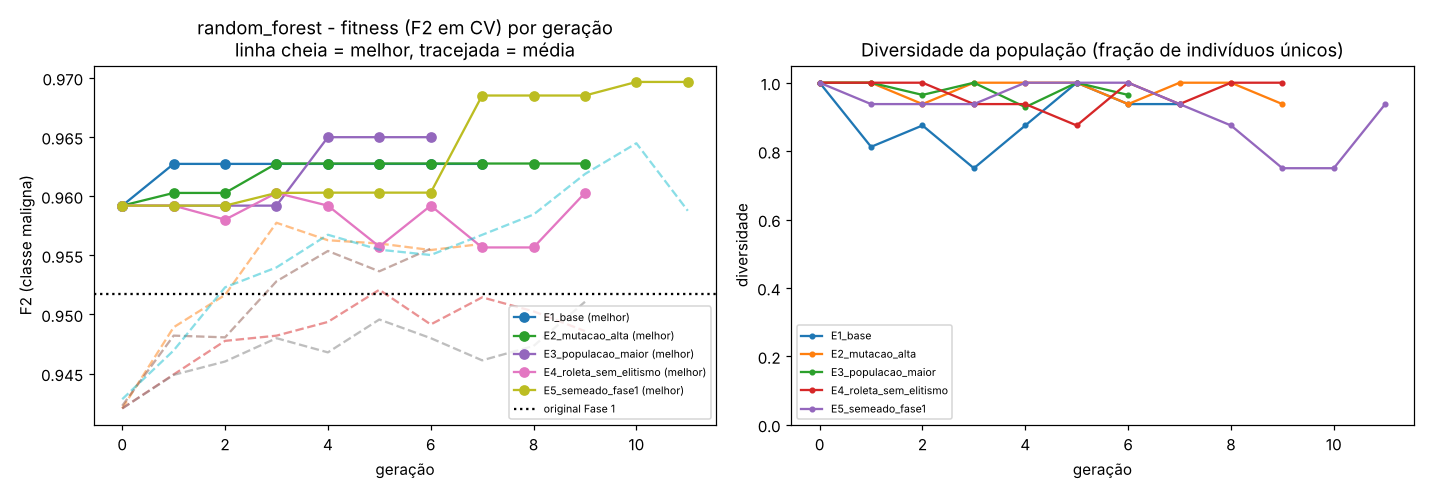

**convergencia_logistic_regression**

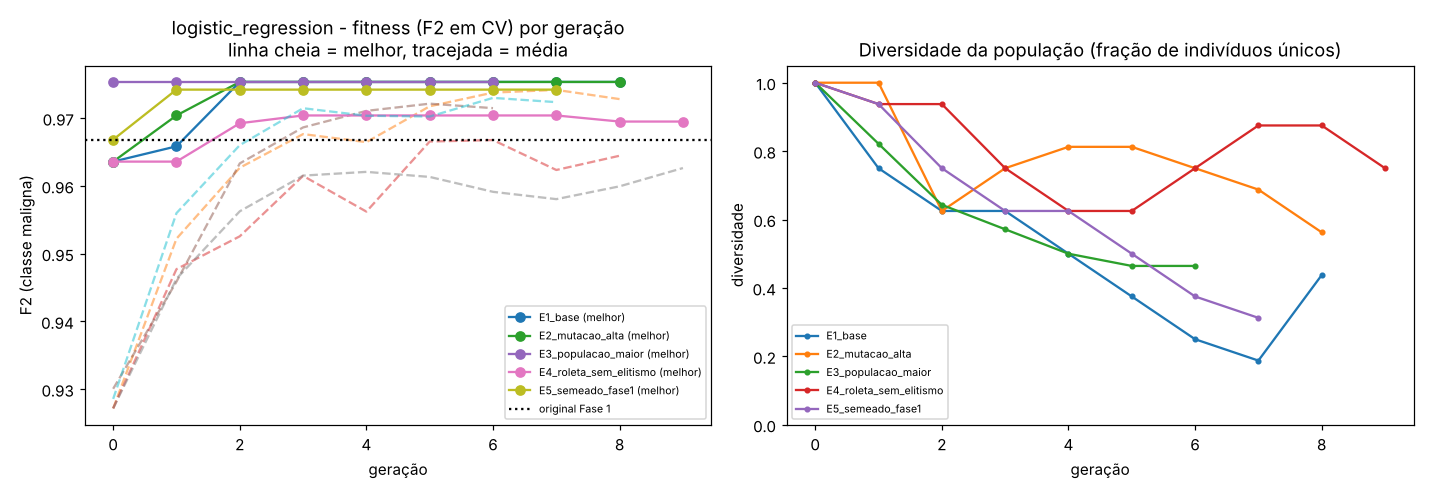

**comparacao_abordagens**

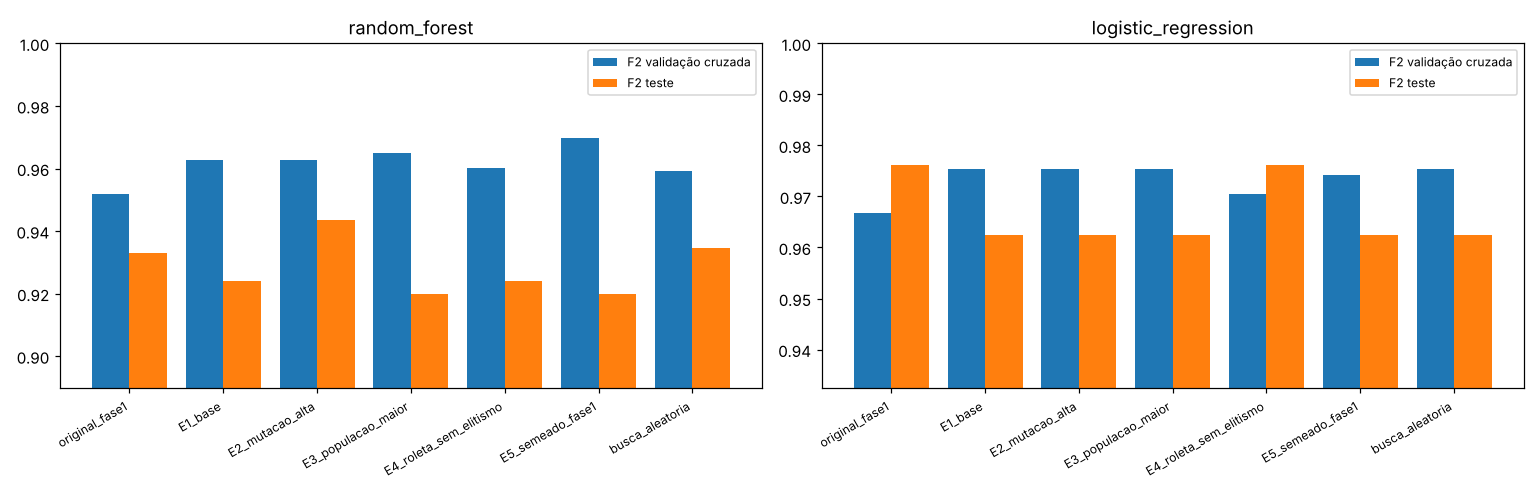

**matriz_confusao_random_forest**

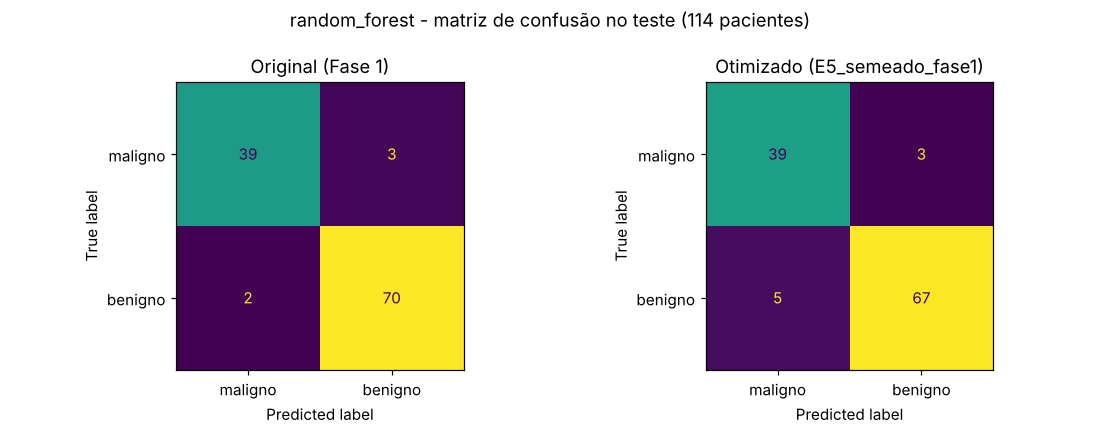

**matriz_confusao_logistic_regression**

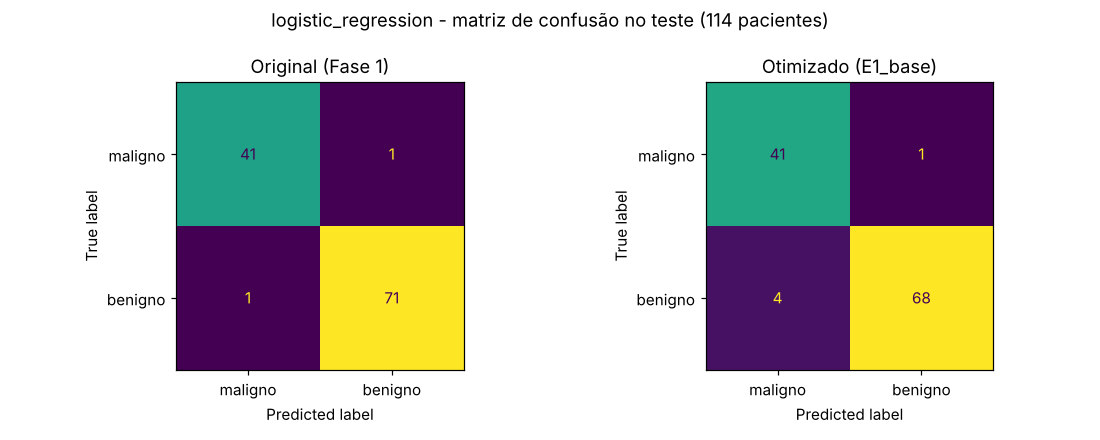

In [5]:
for name in ['convergencia_random_forest', 'convergencia_logistic_regression',
             'comparacao_abordagens', 'matriz_confusao_random_forest', 'matriz_confusao_logistic_regression']:
    display(Markdown(f'**{name}**')); display(Image(filename=str(ROOT / 'results' / f'{name}.png')))

## 4. Interpretação com LLM
O modelo otimizado faz a previsão, o SHAP explica, a LLM traduz para o médico.
Sem chave no `.env`, o cliente cai no modo **offline** (template).

In [6]:
import joblib
from tc2.explain import CaseBuilder
from tc2.llm.client import LLMClient
from tc2.llm.prompts import build_explanation_prompt, offline_explanation
from tc2.llm.evaluation import evaluate_explanation
res_all = json.loads((ROOT / 'results' / 'resultados_completos.json').read_text(encoding='utf-8'))
model_name = max(res_all, key=lambda m: res_all[m][res_all[m]['melhor']['experimento']]['cv']['fitness'])
pipe = joblib.load(ROOT / 'results' / 'models' / f'{model_name}_otimizado.joblib')
metrics = evaluate(pipe, data.X_test, data.y_test)
builder = CaseBuilder(pipe, data.X_train, data.X, data.y, f'{model_name} otimizado por AG',
                      {k: metrics[k] for k in ('recall_maligno', 'precision_maligno', 'accuracy')})
proba = pipe.predict_proba(data.X_test)[:, 0]
idx = data.X_test.index[abs(proba - 0.5).argmin()]   # caso mais incerto
case = builder.build(data.X_test.loc[idx], idx)
print(json.dumps(case, ensure_ascii=False, indent=2)[:1500])

Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


{
  "paciente_id": "526",
  "modelo": "logistic_regression otimizado por AG",
  "previsao": "benigno",
  "probabilidade_maligno": 0.452,
  "probabilidade_maligno_pct": 45.2,
  "nivel_confianca": "baixa (zona de incerteza)",
  "fatores_principais": [
    {
      "caracteristica": "simetria (pior valor)",
      "nome_original": "worst symmetry",
      "valor_paciente": 0.3518,
      "media_casos_malignos": 0.3235,
      "media_casos_benignos": 0.2702,
      "impacto_shap": 0.7667,
      "efeito": "aumenta a chance de malignidade"
    },
    {
      "caracteristica": "suavidade (pior valor)",
      "nome_original": "worst smoothness",
      "valor_paciente": 0.1624,
      "media_casos_malignos": 0.1448,
      "media_casos_benignos": 0.125,
      "impacto_shap": 0.738,
      "efeito": "aumenta a chance de malignidade"
    },
    {
      "caracteristica": "raio (erro padrão)",
      "nome_original": "radius error",
      "valor_paciente": 0.1998,
      "media_casos_malignos": 0.6091,
      

In [7]:
client = LLMClient()
system, user = build_explanation_prompt(case)
text = client.complete(system, user, offline_fallback=lambda: offline_explanation(case))
print('Provedor:', client.provider, client.model)
display(Markdown(text))
evaluate_explanation(text, case)

Provedor: offline template


## Resumo
O modelo (logistic_regression otimizado por AG) classificou o caso como **benigno**, com probabilidade estimada de malignidade de 45.2%.

## Fatores que mais pesaram
- **Simetria (pior valor): 0.3518** - média em casos malignos 0.3235 e em benignos 0.2702; aumenta a chance de malignidade.
- **Suavidade (pior valor): 0.1624** - média em casos malignos 0.1448 e em benignos 0.125; aumenta a chance de malignidade.
- **Raio (erro padrão): 0.1998** - média em casos malignos 0.6091 e em benignos 0.2841; reduz a chance de malignidade.
- **Pontos côncavos (pior valor): 0.1427** - média em casos malignos 0.1822 e em benignos 0.0744; aumenta a chance de malignidade.
- **Compacidade (erro padrão): 0.0144** - média em casos malignos 0.0323 e em benignos 0.0214; aumenta a chance de malignidade.

## Confiança do resultado
Nível de confiança: baixa (zona de incerteza). No conjunto de teste o modelo teve recall de 0.9762 e precisão de 0.9111 para casos malignos.

## Próximos passos sugeridos
- Correlacionar com exame clínico e de imagem.
- Em caso de suspeita ou baixa confiança, considerar biópsia/histopatológico.

## Limitações
Ferramenta de apoio à decisão: não substitui a avaliação do médico. Considera apenas as medidas citológicas do exame, sem histórico clínico, imagem ou fatores de risco.

{'estrutura': 1.0,
 'classe_correta': 1.0,
 'cobertura_fatores': 1.0,
 'fidelidade_numerica': 1.0,
 'seguranca': 1.0,
 'tamanho_adequado': 1.0,
 'nota_geral': 1.0,
 'palavras': 204,
 'numeros_sem_suporte': []}